In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from scipy import stats
import pandas as pd
import seaborn as sns

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal

# Functions with different n values

In [2]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

In [42]:

def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y
    

# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Create a function with the n values baked in that matches AndersonAcceleration signature
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_g, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

In [4]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_626_samples_n_different.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (626, 12)
Number of samples: 626
Number of parameters per sample: 12


# Stability check

In [5]:
# Define the dynamics function F(s, theta, x, m) with different n values
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=2.333, n_b=0.9, n_g=2.0626, n_y=1.562):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)

    # Compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)

    # Compute new g from current r
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g)

    # Compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_g, n_y):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_b, n_g, n_y)

    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=2.333, n_b=0.9, n_g=2.0626, n_y=1.562):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_g, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }


In [8]:
# Use a subset of samples for faster analysis
n_samples_to_analyze = 5 #theta_opt.shape[0]
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")


Using 5 samples for analysis


In [9]:
# Analyze stability

stability_results_all = {}

n_r = 2.333
n_b = 0.9
n_g = 2.0626
n_y = 1.562


stability_results = []
max_real_parts = []
min_real_parts = []
all_eigenvalues = []

for i in range(n_samples_to_analyze):
    theta_star = theta_subset[i, :]

    # Get fixed point outputs with new n values
    try:
        r_star, g_star, b_star, y_star = mitral_output(theta_star, x, m, n_r, n_b, n_g, n_y)

        # Construct state vector s* = [r, g, y]
        s_star = jnp.concatenate([r_star, g_star, y_star])

        # Verify it's a fixed point
        s_prime = F(s_star, theta_star, x, m, n_r, n_b, n_g, n_y)
        s_error = jnp.linalg.norm(s_prime - s_star)

        if s_error > 1e-3:
            print(f"  Sample {i+1}: Warning - fixed point error = {s_error:.2e}")

        # Compute stability
        result = compute_stability(F, s_star, theta_star, x, m, tau=1.0, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
        stability_results.append(result)

        max_real_parts.append(np.max(result['real_parts']))
        min_real_parts.append(np.min(result['real_parts']))
        all_eigenvalues.append(result['eigenvalues'])

    except Exception as e:
        print(f"  Sample {i+1}: Error - {e}")
        continue


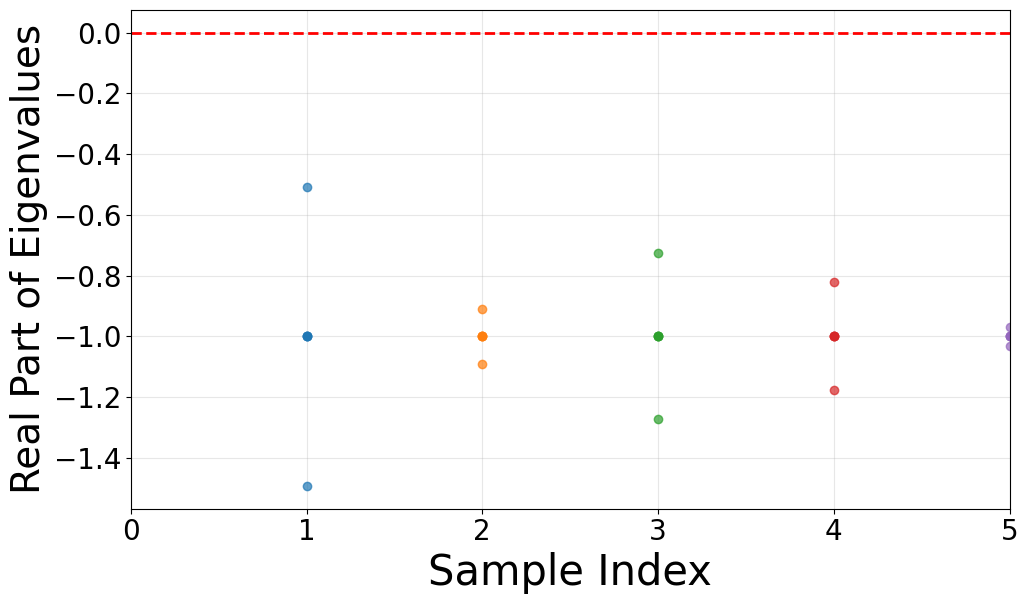


STABILITY SUMMARY

Stable samples: 5/5 (100.0%)


In [10]:
# visualise stability results
fig, ax1 = plt.subplots(1, 1, figsize=(10, 6))

# use actual number of samples
actual_no_samples = len(stability_results)
for i in range(actual_no_samples):
    real_parts = stability_results[i]['real_parts']
    ax1.plot([i+1] * len(real_parts), real_parts, 'o', alpha=0.7, label=f'Sample {i+1}' if i < 5 else '')
ax1.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Stability threshold')
ax1.set_xlabel('Sample Index', fontsize=30)
ax1.set_ylabel('Real Part of Eigenvalues', fontsize=28)
actual_no_samples = len(stability_results)
ax1.set_xlim(0, actual_no_samples)
ax1.grid(True, alpha=0.3)

stable_count = sum(1 for r in stability_results if r['is_stable'])
unstable_count = actual_no_samples - stable_count

plt.tight_layout()
plt.tick_params(axis='both', direction='out')
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
#plt.savefig('Figures/stability.eps')
plt.show()

# print summary
print("\n" + "=" * 70)
print("STABILITY SUMMARY")
print("=" * 70)
print(f"\nStable samples: {stable_count}/{actual_no_samples} ({100*stable_count/actual_no_samples:.1f}%)")

In [23]:
# remove unstable theta
theta_opt = np.array(theta_opt)

# Identify unstable samples from stability_results
remove_row = [i for i, r in enumerate(stability_results) if not r['is_stable']]

max_index = theta_opt.shape[0] - 1
valid_remove_row = [i for i in remove_row if 0 <= i <= max_index]

for i in sorted(valid_remove_row, reverse=True):
    theta_opt = np.delete(theta_opt, i, axis=0)

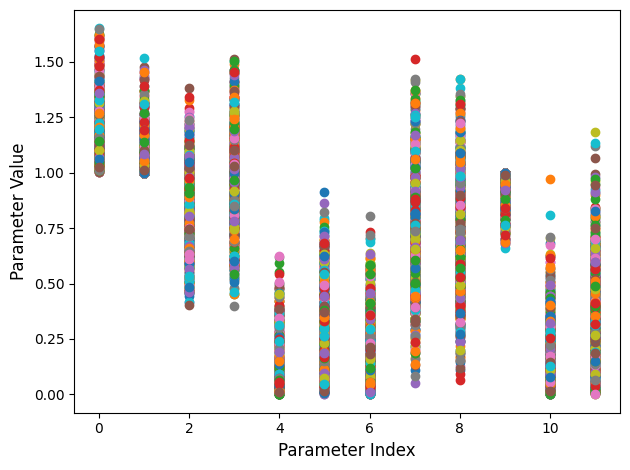

In [11]:
# raw values
for i in range(theta_opt.shape[0]):
    plt.plot(theta_opt[i, :], marker='o', linestyle=' ')
plt.xlabel('Parameter Index', fontsize=12)
plt.ylabel('Parameter Value', fontsize=12)
#plt.xlim(0,30)
plt.tight_layout()
plt.show()


# Compute Hessian

Processing 626 samples...
  Sample 1/626...
  Sample 101/626...
  Sample 201/626...
  Sample 301/626...
  Sample 401/626...
  Sample 501/626...
  Sample 601/626...
Completed processing 626 samples


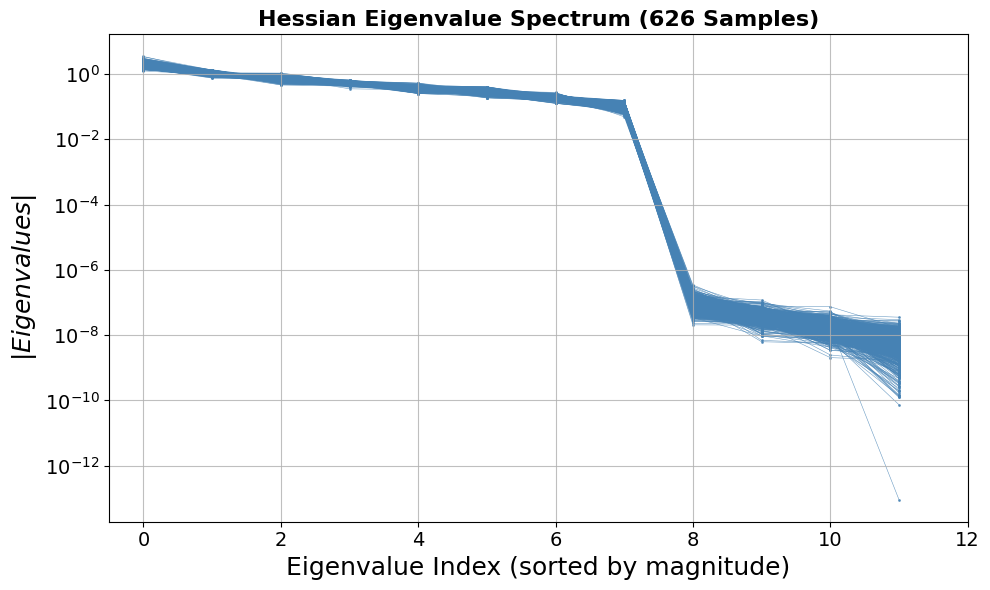

In [12]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_g, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.8, color='steelblue', zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(-0.5, n_params)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.grid(True, alpha=0.8)
ax.set_title(f'Hessian Eigenvalue Spectrum ({n_samples} Samples)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

In [13]:

threshold = 1e-5  # Threshold for near-zero eigenvalues

def get_subspace2_eigenvectors(sample_idx, all_eigenvalues, all_eigenvectors, threshold=1e-5):

    eigenvalues = all_eigenvalues[sample_idx, :]
    eigenvectors = all_eigenvectors[sample_idx, :, :]  # Shape: (n_params, n_params)

    # Find indices where eigenvalues < threshold
    near_zero_mask = eigenvalues < threshold
    n_near_zero = np.sum(near_zero_mask)

    # Extract corresponding eigenvectors (each column is an eigenvector)
    eigenvectors_subspace2 = eigenvectors[:, near_zero_mask].T  # Shape: (n_near_zero, n_params)

    return eigenvectors_subspace2

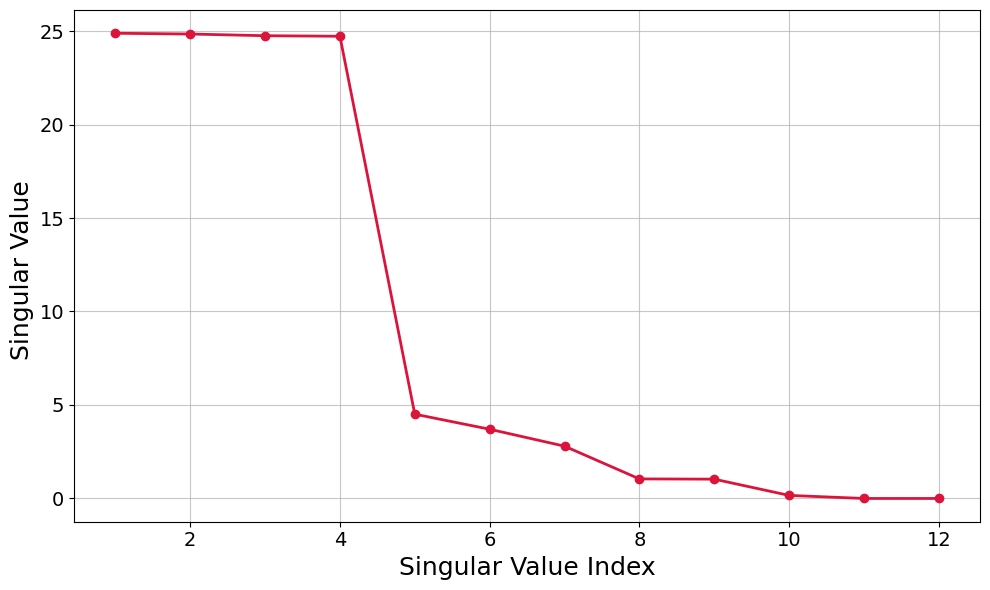

In [14]:

# Concatenate all near-zero eigenvectors from all samples
all_eigenvectors_subspace2 = []
for i in range(n_samples):
    vecs = get_subspace2_eigenvectors(i, all_eigenvalues, all_eigenvectors, threshold=threshold)
    all_eigenvectors_subspace2.append(vecs)
# Stack all (variable-sized, so use vstack)
eigenvectors_concat = np.vstack(all_eigenvectors_subspace2)  # Shape: (total_vectors, n_params)

# Perform SVD on concatenated eigenvectors
U, S, Vt = np.linalg.svd(eigenvectors_concat, full_matrices=False)

# Plot singular values vs index
plt.figure(figsize=(10, 6))
plt.plot(np.arange(1, len(S)+1), S, 'o-', color='crimson', lw=2, ms=6)
plt.xlabel('Singular Value Index', fontsize=18)
plt.ylabel('Singular Value ', fontsize=18)
plt.grid(True, alpha=0.7)
plt.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

In [15]:
Vt[:4].shape # orthonormal rows
Vt[:4].T.shape # orthonormal columns

(12, 4)

In [16]:
def sparse_rotation(U):

    def loss(qtilde):
        """Loss function: mean of absolute values of rotated u"""
        q, _ = jnp.linalg.qr(qtilde) 
        u_rotated = U @ q
        return jnp.mean(jnp.abs(u_rotated))


    # Initialise Adam optimizer
    key = jax.random.PRNGKey(0)
    key, subkey = jax.random.split(key)
    k = U.shape[1]  # Number of columns
    qtilde = jax.random.normal(subkey, (k, k))  # Fixed: should be (k, k) not (r, k)
    optimizer = optax.adam(learning_rate=0.004, eps=1e-4)
    opt_state = optimizer.init(qtilde)


    # Create value_and_grad function
    loss_value_and_grad = jax.value_and_grad(loss)

    # Optimization loop
    for iteration in range(10000):
        loss_value, grads = loss_value_and_grad(qtilde)
        updates, opt_state = optimizer.update(grads, opt_state)
        qtilde = optax.apply_updates(qtilde, updates)
        
        if iteration % 1000 == 0:
            print(f"Iteration {iteration}, Loss: {float(loss_value)}")

    # Get optimized q
    q_opt,_ = jnp.linalg.qr(qtilde)

    U_sparse = U @ q_opt
    return U_sparse

U_sparse = sparse_rotation(Vt[:4].T)

Iteration 0, Loss: 0.19621458649635315
Iteration 1000, Loss: 0.14642536640167236
Iteration 2000, Loss: 0.14639906585216522
Iteration 3000, Loss: 0.1464841663837433
Iteration 4000, Loss: 0.14642731845378876
Iteration 5000, Loss: 0.14640960097312927
Iteration 6000, Loss: 0.14648234844207764
Iteration 7000, Loss: 0.14641325175762177
Iteration 8000, Loss: 0.1464201807975769
Iteration 9000, Loss: 0.14640626311302185


In [17]:
U_sparse.shape

(12, 4)

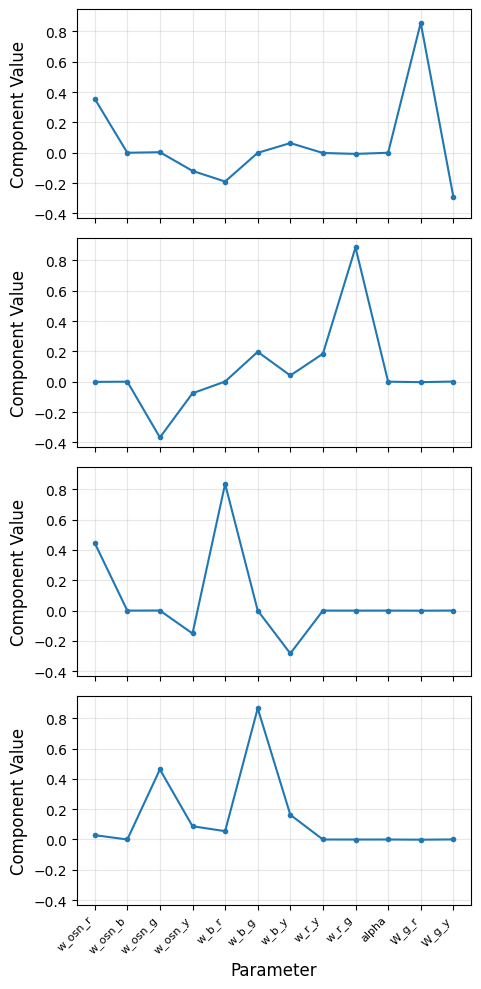

In [18]:
# Use U_sparse from smoothed sparse rotation
M = U_sparse  # Shape: (28 params, 11 components)

# Create parameter labels in the correct order
param_labels = [
    'w_osn_r',
    'w_osn_b',
    'w_osn_g',
    'w_osn_y',
    'w_b_r',
    'w_b_g',
    'w_b_y',
    'w_r_y',
    'w_r_g',
    'alpha',
    'W_g_r',
    'W_g_y'
]

# Sort components by sparsity (sum of absolute values)
M_sums = np.abs(M).sum(0)
sorting_ind = np.argsort(M_sums)[::-1]
M_plot = M[:, sorting_ind]

# Get number of components
n_components = M_plot.shape[1]

# Calculate grid size 
n_rows, n_cols = 4, 1
fig, ax = plt.subplots(figsize=(5, 10), nrows=n_rows, ncols=n_cols, sharex=True, sharey=True)

# Flatten axes array for easier indexing
ax = ax.flatten()

# Plot all components
for i in range(n_components):
    ax[i].plot(M_plot[:, i], '.-', label=f'Component {sorting_ind[i]+1} (sorted {i+1})')
    ax[i].set_xticks(range(len(param_labels)))
    ax[i].set_xticklabels(param_labels, rotation=45, ha='right', fontsize=8)
    ax[i].grid(True, alpha=0.3)
    

# Hide unused subplots
for i in range(n_components, n_rows * n_cols):
    ax[i].axis('off')

# Set labels for bottom row
for col in range(n_cols):
    row_idx = (n_rows - 1) * n_cols + col
    if row_idx < n_components:
        ax[row_idx].set_xlabel('Parameter', fontsize=12)

# Set labels for left column
for row in range(n_rows):
    col_idx = row * n_cols
    if col_idx < n_components:
        ax[col_idx].set_ylabel('Component Value', fontsize=12)

plt.tight_layout()
plt.show()

# Step in Delta Theta

In [24]:
print(theta_opt[:2].shape)
print(U_sparse.T.shape)
print(M_plot.shape)

(2, 12)
(4, 12)
(12, 4)


In [34]:

U_sparse_jax = jnp.array(U_sparse.T)

# Create a key for the random row
key = jax.random.PRNGKey(0)  # or reuse an existing key
random_row = jax.random.normal(key, (1, U_sparse_jax.shape[1]))

U_sparse_jax = jnp.vstack([U_sparse_jax, random_row])
U_sparse_jax[2].shape

(12,)

ValueError: All input arrays must have the same shape.

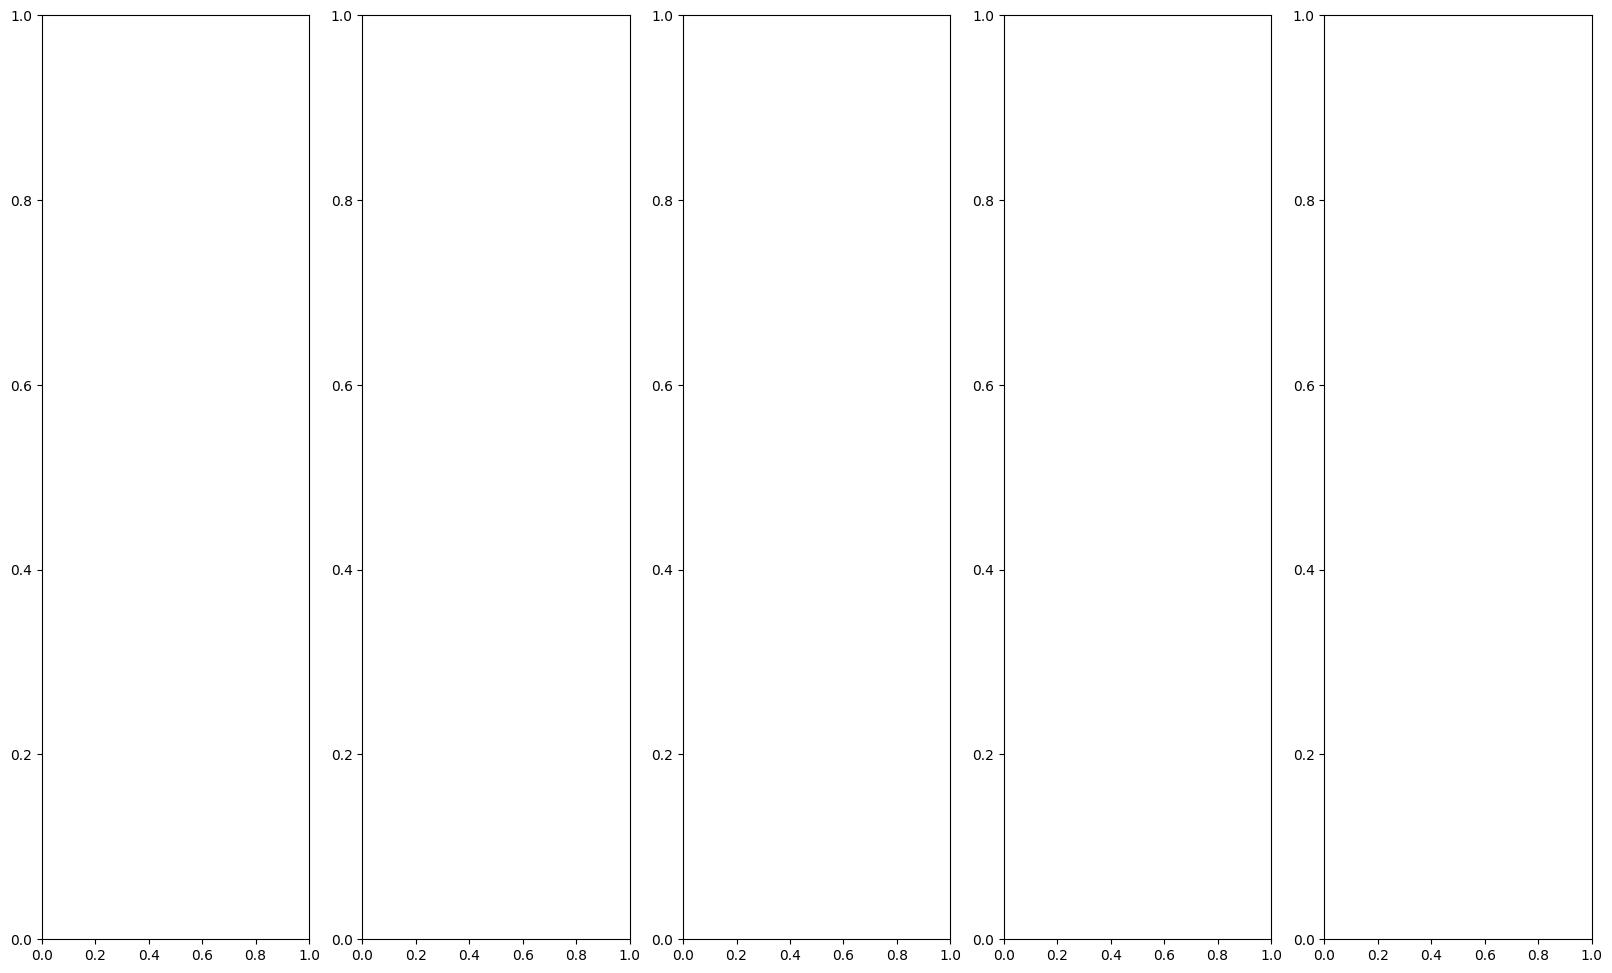

In [44]:
e = np.arange(-2, 2+0.2, 0.2)
n_samples = 1  # Number of samples to process

# Select subset of theta_opt first and convert to JAX array
theta_opt_subset = jnp.array(theta_opt[:n_samples])  # Shape: (n_samples, n_params)
# Use U_sparse as (n_params, n_components) so column k has length n_params for correct broadcasting
U_sparse_jax = jnp.array(U_sparse)  # Shape: (n_params, n_components) e.g. (12, 4)
# Add 5th random component as a new column
key = jax.random.PRNGKey(0)
random_col = jax.random.normal(key, (U_sparse_jax.shape[0], 1))
U_sparse_jax = jnp.hstack([U_sparse_jax, random_col])  # Shape: (n_params, 5)

fig, ax = plt.subplots(1, 5, figsize=(20, 12))
ax = ax.flatten()  # Flatten to 1D array for easier indexing

for k in range(5):  # 5 components (4 sparse + 1 random) 
    y_save = []  # Reset for each component

    for i in range(len(e)):
        # U_sparse_jax[:, k] has shape (n_params,) so (n_samples, n_params) + (n_params,) broadcasts correctly
        theta_step = theta_opt_subset + e[i] * U_sparse_jax[:, k]

        y_samples = []
        for j in range(theta_step.shape[0]):  # Iterate over n_samples
            # Extract row and convert to numpy array first, then pass to unpack_theta
            theta_row = np.array(theta_step[j])  # Convert JAX to numpy first
            theta_unpack = unpack_theta(theta_row, m)
            r, g, b, y = mitral_output(theta_unpack, x, m, n_r, n_b, n_g, n_y)
            # Convert JAX array to numpy for storage
            y_samples.append(np.array(y))
            print(f"Delta_theta {k}, Epsilon {i}, Sample {j}")

        y_save.append(np.array(y_samples))  # Shape: (n_samples, m)

    # Convert to array: Shape: (len(e), n_samples, m)
    y_array = np.array(y_save)

    # Plot in subplot k
    for sample_idx in range(n_samples):
        ax[k].plot(e, y_array[:, sample_idx, 0], color='blue', alpha=0.7, label=f'y[0] sample {sample_idx}' if sample_idx == 0 else '')
        ax[k].plot(e, y_array[:, sample_idx, 1], color='red', alpha=0.7, label=f'y[1] sample {sample_idx}' if sample_idx == 0 else '')

    ax[k].set_xlabel('Epsilon (e)')
    ax[k].set_ylabel('Output y')
    ax[k].set_title(f'Component {k+1}')
    ax[k].grid(True, alpha=0.3)
    if k == 0:  # Add legend only to first subplot
        ax[k].legend(fontsize=8)

plt.tight_layout()
plt.show()